# Clase 6 — Controlar sin mapa: SARSA y Q-learning

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Sutton & Barto, cap. 2.2–2.3 ($\varepsilon$-greedy) y cap. 6 (6.4 SARSA, 6.5 Q-learning), en Stanford CS234 (Brunskill), clase 4 (primera mitad), y en Watkins y Dayan (1992).

**La pregunta de hoy:** sin mapa, ¿cómo encontrás la salida si para saber qué conviene tenés que probar, y probar cuesta?

En la clase 5 el agente **evaluaba** una política que le dábamos. Hoy la tiene que **elegir** él, y sigue sin tener `env.P` ni `env.R`: solo juega. Nosotros sí tenemos el mapa y lo usamos para una sola cosa: calcular la respuesta correcta ($Q^*$ y $V^*$ por iteración de valor, como en la clase 4) y ver qué tan cerca queda el agente. Vamos a ver:

1. **Por qué $Q$ y no $V$**: sin mapa, $V$ no alcanza para elegir.
2. **$\varepsilon$-greedy**: probar a veces, y qué pasa con $\varepsilon = 0$ y con $\varepsilon = 1$.
3. **SARSA**: una actualización a mano, con números.
4. **Q-learning**: la misma experiencia, con la otra regla.
5. **SARSA contra Q-learning con varios $\varepsilon$**: qué valor aprende cada uno.
6. **El mapa de visitas**: dónde se equivoca lo aprendido.

Y un ejercicio: cambiar $\varepsilon$ y $\alpha$.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda alrededor de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre, y fijamos una semilla. Las convenciones son las de las clases 3 a 5: **+1 al entrar a la salida**, la salida es absorbente y vale 0 (ahí ya no queda nada por cobrar), el primer paso no se descuenta y $\gamma = 0{,}99$. Las partidas duran como mucho 200 pasos, como en el juego.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
GAMMA = 0.99
env = CaveEnv(max_steps=200)

La celda siguiente define las **herramientas** (la respuesta correcta con el mapa, el agente que aprende y los dibujos). Está plegada: no hace falta leerla, solo ejecutarla.

Una aclaración importante: la función que **aprende** (`aprender`) y la que juega una partida (`jugar`) solo usan `env.reset` y `env.step`, como un jugador en la cueva a oscuras. El mapa (`env.P`, `env.R`) lo usan solo `iteracion_de_valor` y `valor_explorando`, que calculan la respuesta correcta para comparar.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
COL_SARSA, COL_Q = COLORES[6], COLORES[2]
NOMBRE = {"sarsa": "SARSA", "q": "Q-learning"}
COLOR = {"sarsa": COL_SARSA, "q": COL_Q}


# ---------- la respuesta correcta (esto SÍ usa el mapa) ----------
def iteracion_de_valor(env, gamma, tol=1e-12):
    """Clase 4: V(s) <- max_a [R(s,a) + γ Σ P(s'|s,a) V(s')]. Devuelve V* y Q*."""
    V = np.zeros(env.nS)
    while True:
        V_nuevo = (env.R + gamma * env.P @ V).max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            return V_nuevo, env.R + gamma * env.P @ V_nuevo
        V = V_nuevo


def valor_explorando(env, gamma, eps, tol=1e-12):
    """Lo que vale cada flecha si después se sigue jugando ε-greedy (la mejor flecha con prob. 1−ε, el dado con ε),
    eligiendo siempre lo mejor que se puede elegir así. Es el valor al que llega SARSA con ε fijo."""
    Q = np.zeros((env.nS, env.nA))
    while True:
        V = (1 - eps) * Q.max(axis=1) + eps * Q.mean(axis=1)
        Q_nuevo = env.R + gamma * env.P @ V
        if np.max(np.abs(Q_nuevo - Q)) < tol:
            return Q_nuevo
        Q = Q_nuevo


def acciones_optimas(Q_estrella):
    """Máscara [s, a]: True si a es óptima en s (puede haber empates)."""
    return np.isclose(Q_estrella, Q_estrella.max(axis=1, keepdims=True), rtol=0, atol=1e-9)


def frac_optimas(env, Q, opt, casillas=None):
    """Fracción de casillas (sin la salida) en las que la flecha de mayor Q aprendido es óptima."""
    ss = [s for s in range(env.nS) if s != env.goal] if casillas is None else list(casillas)
    flechas = Q.argmax(axis=1)
    return float(np.mean([opt[s, flechas[s]] for s in ss]))


def pasos_de(v, gamma=0.99):
    """Si el único premio es el +1 al entrar, V = γ^(n−1): un camino de n pasos."""
    return 1 + np.log(v) / np.log(gamma)


# ---------- el agente sin mapa: solo env.reset y env.step ----------
def inicio_al_azar(env, rng):
    """Una casilla al azar que no sea la salida."""
    s = int(rng.integers(env.nS - 1))
    return s if s < env.goal else s + 1


def q_inicial(env, rng):
    """Q arranca en 0 más un ruido minúsculo (entre 0 y 0,0001): sin ruido, todo empata."""
    return rng.uniform(0, 1e-4, size=(env.nS, env.nA))


def aprender(env, metodo, eps, alfa, n_partidas, semilla, gamma=0.99, inicio="S"):
    """SARSA (metodo="sarsa") o Q-learning (metodo="q") con ε-greedy, desde S o desde una casilla al azar.
    En cada paso:  Q(s,a) += α [objetivo − Q(s,a)]  con
        SARSA:      objetivo = r + γ Q(s', a')      (a' = la acción que de verdad va a tomar)
        Q-learning: objetivo = r + γ max_a' Q(s', a')
    Al entrar a la salida, objetivo = r (ahí ya no queda nada por cobrar).
    Devuelve Q, pasos y salida de cada partida, visitas[partida, casilla] y V(S) = max_a Q(S, a) al final de cada partida."""
    rng = np.random.default_rng(semilla)
    Q = q_inicial(env, rng).tolist()              # listas de Python: más rápido que numpy para filas de 4
    pasos = np.zeros(n_partidas, int); salio = np.zeros(n_partidas, bool)
    visitas = np.zeros((n_partidas, env.nS), np.int32); VS = np.zeros(n_partidas)
    B = 8192; dado = rng.random(B); azar = rng.integers(env.nA, size=B); j = [0]

    def elegir(s):                                # ε-greedy
        k = j[0]
        if k == B:
            dado[:] = rng.random(B); azar[:] = rng.integers(env.nA, size=B); k = 0
        j[0] = k + 1
        if dado[k] < eps:
            return int(azar[k])                   # probar: cualquiera de las 4
        q = Q[s]
        return q.index(max(q))                    # aprovechar: la de mayor Q

    sarsa = metodo == "sarsa"
    for k in range(n_partidas):
        s = env.reset()
        if inicio == "azar":
            s = inicio_al_azar(env, rng); env.s = s
        a = elegir(s); vis = visitas[k]; vis[s] += 1
        while True:
            s2, r, fin, info = env.step(a); vis[s2] += 1
            a2 = elegir(s2)
            if info["reached_goal"]:
                objetivo = r
            elif sarsa:
                objetivo = r + gamma * Q[s2][a2]
            else:
                objetivo = r + gamma * max(Q[s2])
            Q[s][a] += alfa * (objetivo - Q[s][a])
            s, a = s2, a2
            if fin:
                break
        pasos[k] = env.t; salio[k] = info["reached_goal"]; VS[k] = max(Q[env.start])
    return {"Q": np.array(Q), "pasos": pasos, "salio": salio, "visitas": visitas, "VS": VS}


def _elegir(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1])), True
    return int(Q[s].argmax()), False


def jugar(env, Q, eps, rng, max_pasos=200):
    """Una partida desde S con ε-greedy sobre Q, SIN aprender. Devuelve la lista de pasos
    (s, a, r, s', a', a' salió al azar)."""
    s = env.reset()
    a, _ = _elegir(Q, s, eps, rng)
    partida = []
    for _ in range(max_pasos):
        s2, r, fin, info = env.step(a)
        a2, al_azar = _elegir(Q, s2, eps, rng)
        partida.append((s, a, r, s2, a2, al_azar))
        s, a = s2, a2
        if info["reached_goal"]:
            break
    return partida


def camino_de(partida):
    return [partida[0][0]] + [x[3] for x in partida]


# ---------- dibujos de la cueva ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None, cmap="magma", clim=None,
              mark=None, numbers=False, fmt="{:.2f}"):
    """env.plot + escala de color elegible (calculada sin la salida), flechas con borde, círculos y números opcionales."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            v = v[np.isfinite(v)]
            clim = (v.min(), v.max()) if v.size else (0, 1)
            if clim[1] - clim[0] < 1e-12:
                clim = (clim[1] - 1, clim[1])
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        for m in np.atleast_1d(mark):
            r, c = env.free[int(m)]
            ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if np.isfinite(values[s]) and s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def plot_agent_view(env, partida, ax, title):
    """Lo que 've' el agente: solo las paredes que tocó (gris claro) y su recorrido."""
    tocadas = set()
    for s, a, r, s2, *_ in partida:
        if s2 == s:
            (fr, fc), (dr, dc) = env.free[s], [(-1, 0), (0, 1), (1, 0), (0, -1)][a]
            tocadas.add((fr + dr, fc + dc))
    env.plot(ax=ax, show_walls=False, path=camino_de(partida), title=title)
    for (r, c) in tocadas:
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=(0.8, 0.8, 0.8)))
    return tocadas


def plot_casilla(env, s, ax, V=None, Q=None, title=None, radio=2, clim=None):
    """Zoom alrededor de la casilla s. Con V: el valor de cada casilla y un '?' en cada flecha de s.
    Con Q: los cuatro valores de las flechas de s (la mejor, en verde)."""
    r0, c0 = env.free[s]
    vals = V if V is not None else Q.max(axis=1)
    plot_cave(env, values=vals, ax=ax, clim=clim, title=title)
    ax.set_xlim(c0 - radio - .5, c0 + radio + .5); ax.set_ylim(r0 + radio + .5, r0 - radio - .5)
    sombra = [pe.withStroke(linewidth=2.5, foreground="black")]
    desp = [(-0.37, 0), (0, 0.37), (0.37, 0), (0, -0.37)]
    for t in ax.texts:
        t.set_clip_on(True)
    if V is not None:
        for s2, (r, c) in enumerate(env.free):
            if abs(r - r0) <= radio and abs(c - c0) <= radio and s2 != env.goal:
                ax.text(c, r, f"{V[s2]:.3f}", ha="center", va="center", fontsize=9, color="w", path_effects=sombra)
        for (dr, dc) in desp:
            ax.text(c0 + 1.35 * dc, r0 + 1.35 * dr, "?", ha="center", va="center", fontsize=14, color="#ffd400",
                    weight="bold", path_effects=sombra)
    else:
        best = int(Q[s].argmax())
        for a, (dr, dc) in enumerate(desp):
            ax.text(c0 + 0.8 * dc, r0 + dr, f"{ACTION_NAMES[a]} {Q[s, a]:.3f}", ha="center", va="center",
                    fontsize=9, color="#7CFC00" if a == best else "w", weight="bold" if a == best else None,
                    path_effects=sombra)
    ax.plot(c0, r0, "s", mfc="none", mec="#00e5ff", mew=2, ms=38)


def suavizar(x, w=20):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")


def banda(ax, x, y, color, label, ls="-"):
    """Promedio sobre semillas y banda de ± 1 desvío."""
    m, sd = y.mean(0), y.std(0)
    ax.plot(x, m, color=color, label=label, ls=ls)
    ax.fill_between(x, m - sd, m + sd, color=color, alpha=0.15, lw=0)

## 1. Por qué $Q$ y no $V$

En la clase 4, con el mapa, elegir era fácil: para cada flecha se hace la cuenta

$$Q(s, a) = R(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V(s')$$

y se elige la de mayor $Q$. Pero esa cuenta **necesita $P$**: saber adónde lleva cada flecha. Sin mapa, aunque alguien le soplara al agente el $V$ exacto de cada casilla, no sabría qué flecha lo lleva a la casilla que vale más.

### Paso 1 — La respuesta correcta (solo para comparar)

Calculamos $V^*$ y $Q^*$ por iteración de valor, con el mapa, como en la clase 4. El agente nunca ve esto.

In [4]:
V_estrella, Q_estrella = iteracion_de_valor(env, GAMMA)
opt = acciones_optimas(Q_estrella)
ng = np.arange(env.nS) != env.goal
cruce = env.pos2s[(5, 6)]

print(f"V*(S) = {V_estrella[env.start]:.4f}   (= 0.99^{pasos_de(V_estrella[env.start]) - 1:.0f}: el camino más corto tiene "
      f"{pasos_de(V_estrella[env.start]):.0f} pasos)")
print("Q*(S, ·):      " + "   ".join(f"{ACTION_NAMES[a]} {Q_estrella[env.start, a]:.4f}" for a in range(env.nA)))
print(f"V*(cruce (5, 6)) = {V_estrella[cruce]:.4f}")
print("Q*(cruce, ·):  " + "   ".join(f"{ACTION_NAMES[a]} {Q_estrella[cruce, a]:.4f}" for a in range(env.nA)))

V*(S) = 0.8262   (= 0.99^19: el camino más corto tiene 20 pasos)
Q*(S, ·):      ↑ 0.8179   → 0.8262   ↓ 0.8097   ← 0.8179
V*(cruce (5, 6)) = 0.9227
Q*(cruce, ·):  ↑ 0.9135   → 0.9227   ↓ 0.9044   ← 0.9044


### Paso 2 — La misma casilla, con $V$ y con $Q$

A la izquierda, el cruce (5, 6) de las clases 3 a 5 con el $V^*$ de cada casilla vecina: sabemos cuánto vale cada lugar, pero no adónde lleva cada flecha (los signos de pregunta). A la derecha, la misma casilla con sus cuatro $Q^*$: un número por flecha, y elegir es mirar cuál es el mayor.

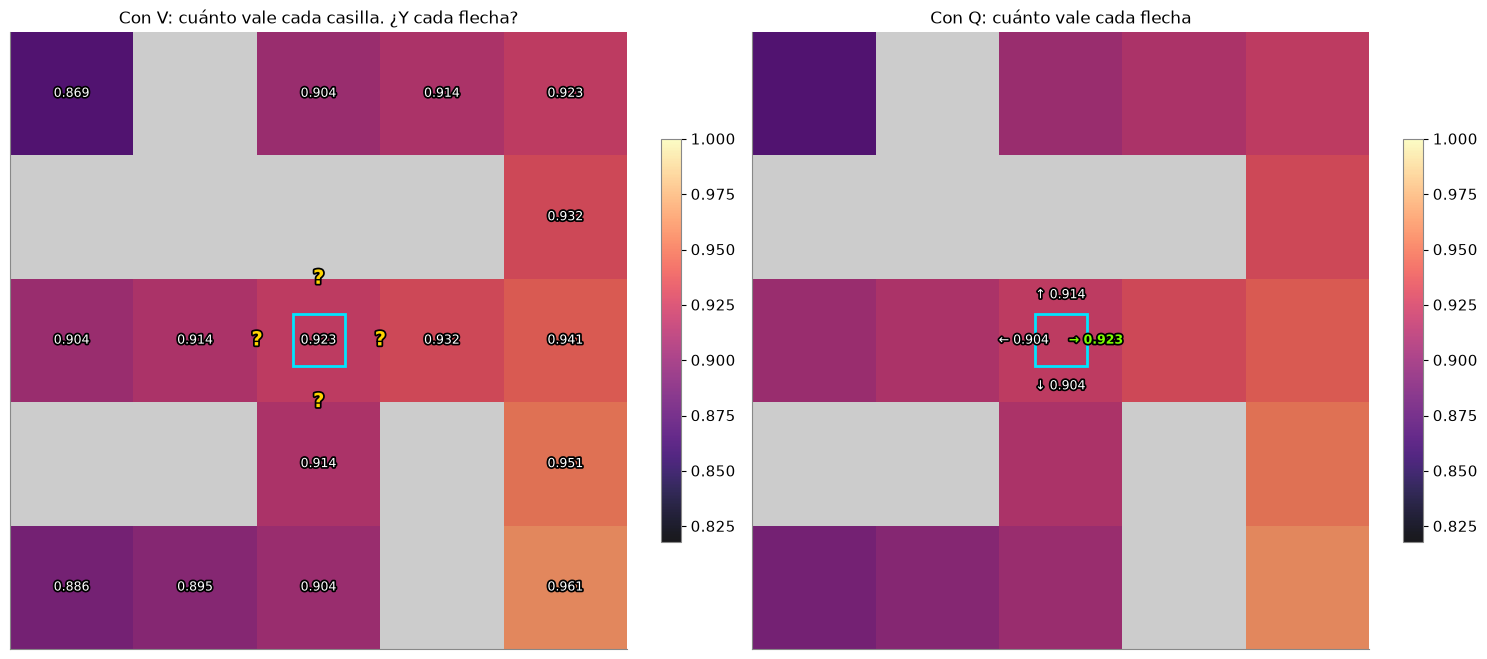

Lo que hace falta para pasar de V a Q en el cruce (esto usa el mapa):
   ↑: P dice que va a (5, 6) (choca y se queda) R = 0   Q = 0 + 0.99 · 0.9227 = 0.9135
   →: P dice que va a (5, 7)                   R = 0   Q = 0 + 0.99 · 0.9321 = 0.9227
   ↓: P dice que va a (6, 6)                   R = 0   Q = 0 + 0.99 · 0.9135 = 0.9044
   ←: P dice que va a (5, 5)                   R = 0   Q = 0 + 0.99 · 0.9135 = 0.9044


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.6))
plot_casilla(env, cruce, axs[0], V=V_estrella, title="Con V: cuánto vale cada casilla. ¿Y cada flecha?")
plot_casilla(env, cruce, axs[1], Q=Q_estrella, title="Con Q: cuánto vale cada flecha")
plt.tight_layout(); plt.show()

print("Lo que hace falta para pasar de V a Q en el cruce (esto usa el mapa):")
for a in range(env.nA):
    s2 = int(np.argmax(env.P[cruce, a]))
    destino = str(env.free[s2]) + (" (choca y se queda)" if s2 == cruce else "")
    print(f"   {ACTION_NAMES[a]}: P dice que va a {destino:24s} R = {env.R[cruce, a]:g}   "
          f"Q = {env.R[cruce, a]:g} + {GAMMA} · {V_estrella[s2]:.4f} = {Q_estrella[cruce, a]:.4f}")

Con $V$ solo, el agente sabe que alguna casilla vecina vale más que otra, pero para saber qué flecha lo lleva ahí necesita $P$ (y en una cueva resbalosa, como la de la clase 4, ni siquiera alcanza con saber la dirección). Con $Q$ no hace falta: el número ya está pegado a la flecha. Por eso, sin mapa, **se aprende directamente $Q(s, a)$**: 60 casillas × 4 flechas = 240 números.

Y ahí aparece el problema de hoy: para saber cuánto vale una flecha, hay que **probarla**.

## 2. Probar a veces: $\varepsilon$-greedy

Si el agente siempre elige la flecha de mayor $Q$ (*greedy*, codicioso), nunca prueba las otras y nunca se entera de si valían más. La receta más simple para probar es **$\varepsilon$-greedy**:

1. Con probabilidad $\varepsilon$, una flecha **al azar** (cualquiera de las cuatro, incluida la mejor): **probar** (*explore*).
2. Si no, la de mayor $Q$: **aprovechar** (*exploit*).

### Paso 1 — Qué probabilidad tiene cada flecha

Con los $Q^*$ de S, la mejor flecha es →. Con $\varepsilon$-greedy, la mejor tiene probabilidad $1 - \varepsilon + \varepsilon/4$ y cada una de las otras, $\varepsilon/4$.

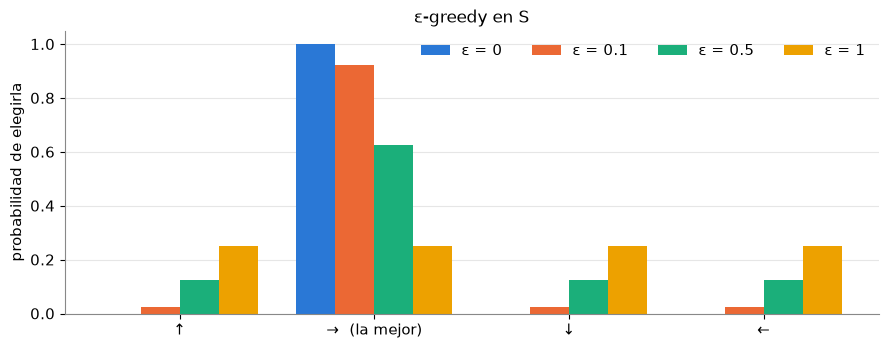

ε = 0    la mejor: 1.000   cada una de las otras: 0.000
ε = 0.1  la mejor: 0.925   cada una de las otras: 0.025
ε = 0.5  la mejor: 0.625   cada una de las otras: 0.125
ε = 1    la mejor: 0.250   cada una de las otras: 0.250


In [6]:
EPS_DEMO = [0, 0.1, 0.5, 1]
mejor = int(Q_estrella[env.start].argmax())
fig, ax = plt.subplots(figsize=(9, 3.6))
ancho = 0.2
for i, e in enumerate(EPS_DEMO):
    p = np.full(env.nA, e / env.nA); p[mejor] += 1 - e
    ax.bar(np.arange(env.nA) + (i - 1.5) * ancho, p, width=ancho, color=COLORES[i], label=f"ε = {e:g}")
ax.set_xticks(range(env.nA))
ax.set_xticklabels([ACTION_NAMES[a] + ("  (la mejor)" if a == mejor else "") for a in range(env.nA)])
ax.set_ylabel("probabilidad de elegirla"); ax.set_title("ε-greedy en S"); ax.legend(frameon=False, ncol=4)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
for e in EPS_DEMO:
    print(f"ε = {e:<4g} la mejor: {1 - e + e / 4:.3f}   cada una de las otras: {e / 4:.3f}")

### Paso 2 — ¿Cuánto probar?

Ahora el agente juega de verdad, sin mapa, desde S, con Q-learning (la regla de la sección 4; por ahora alcanza con saber que aprende de cada paso). Su $Q$ arranca en 0 en todas partes, más un ruido minúsculo (entre 0 y 0,0001): sin ese ruido las cuatro flechas empatarían, y con el ruido cada casilla tiene una preferencia arbitraria, como una costumbre. Como el único premio es el +1 de la salida, **hasta que no la encuentra una vez, todo sigue valiendo casi 0**.

Probamos siete valores de $\varepsilon$, con 300 partidas de hasta 200 pasos, $\alpha = 0{,}2$ y 8 semillas. Medimos dos cosas: **en qué partida encuentra la salida por primera vez** y **cuántos pasos tarda al final** (promedio de las últimas 50 partidas; 200 = no sale).

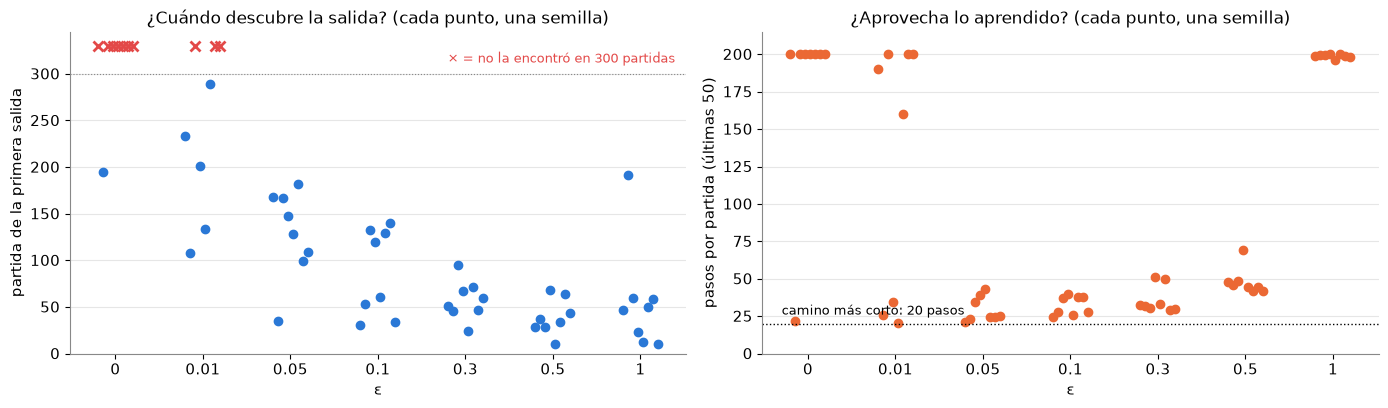

    ε  semillas que la encontraron   partida de la 1.ª salida (mediana)   pasos al final (promedio)
    0                       1 de 8                                  195                       177.8
 0.01                       5 de 8                                  201                       128.8
 0.05                       8 de 8                                  138                        29.4
  0.1                       8 de 8                                   90                        32.3
  0.3                       8 de 8                                   56                        36.0
  0.5                       8 de 8                                   36                        48.0
    1                       8 de 8                                   48                       198.9

partida de la primera salida, semilla por semilla (−1 = nunca):
   ε = 0     [-1, 195, -1, -1, -1, -1, -1, -1]
   ε = 0.01  [233, 108, -1, 201, 134, 289, -1, -1]
   ε = 0.05  [168, 35, 167, 148, 128,

In [7]:
ALFA = 0.2
EPS_BARRIDO = [0, 0.01, 0.05, 0.1, 0.3, 0.5, 1]
N_SEM = 8
barrido = {e: [aprender(env, "q", e, ALFA, 300, sem) for sem in range(N_SEM)] for e in EPS_BARRIDO}

primera = {e: np.array([int(np.argmax(r["salio"])) + 1 if r["salio"].any() else -1 for r in barrido[e]]) for e in EPS_BARRIDO}
finales = {e: np.array([r["pasos"][-50:].mean() for r in barrido[e]]) for e in EPS_BARRIDO}

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
xs = np.arange(len(EPS_BARRIDO))
jit = np.linspace(-0.2, 0.2, N_SEM)
for i, e in enumerate(EPS_BARRIDO):
    f = primera[e]
    axs[0].plot(i + jit[f > 0], f[f > 0], "o", color=COLORES[0], ms=6)
    axs[0].plot(i + jit[f < 0], np.full(np.sum(f < 0), 330), "x", color=COLORES[7], ms=7, mew=2)
    axs[1].plot(i + jit, finales[e], "o", color=COLORES[1], ms=6)
axs[0].axhline(300, color="#888888", lw=0.8, ls=":")
axs[0].text(len(EPS_BARRIDO) - 0.6, 312, "× = no la encontró en 300 partidas", ha="right", fontsize=9, color=COLORES[7])
axs[0].set_ylim(0, 345); axs[0].set_ylabel("partida de la primera salida")
axs[0].set_title("¿Cuándo descubre la salida? (cada punto, una semilla)")
axs[1].axhline(20, color="k", ls=":", lw=1); axs[1].text(-0.3, 26, "camino más corto: 20 pasos", fontsize=9)
axs[1].set_ylim(0, 215); axs[1].set_ylabel("pasos por partida (últimas 50)")
axs[1].set_title("¿Aprovecha lo aprendido? (cada punto, una semilla)")
for ax in axs:
    ax.set_xticks(xs); ax.set_xticklabels([f"{e:g}" for e in EPS_BARRIDO]); ax.set_xlabel("ε"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print(f"{'ε':>5s} {'semillas que la encontraron':>28s} {'partida de la 1.ª salida (mediana)':>36s} {'pasos al final (promedio)':>27s}")
for e in EPS_BARRIDO:
    f = primera[e]
    med = f"{np.median(f[f > 0]):.0f}" if np.any(f > 0) else "—"
    cuantas = f"{np.sum(f > 0)} de {N_SEM}"
    print(f"{e:>5g} {cuantas:>28s} {med:>36s} {finales[e].mean():>27.1f}")
print("\npartida de la primera salida, semilla por semilla (−1 = nunca):")
for e in EPS_BARRIDO:
    print(f"   ε = {e:<5g} {primera[e].tolist()}")

Los dos extremos fallan, cada uno a su manera:

- **Con $\varepsilon = 0$ no prueba nunca**: sigue sus costumbres, que lo dejan dando vueltas siempre por el mismo lado, y en 7 de las 8 semillas no encuentra la salida en 300 partidas. (En la otra la encuentra recién en la partida 195: el ruido inicial, al irse corrigiendo, a veces le cambia una costumbre y lo hace probar algo sin querer.) Con $\varepsilon = 0{,}01$ tampoco alcanza: 3 de 8 semillas no la encuentran.
- **Con $\varepsilon = 1$ prueba siempre**: encuentra la salida como el dado, pero como nunca usa lo aprendido, al final sigue tardando casi 200 pasos por partida.
- En el medio, el agente descubre la salida y después la aprovecha. Entre $\varepsilon = 0{,}05$ y $0{,}5$, cuanto más grande $\varepsilon$, antes la descubre y más pasos gasta en probar al final.

### Paso 3 — Una partida más, después de aprender

Para ver qué hace cada agente con lo que aprendió, la semilla 0 de tres de ellos juega una partida más desde S, con su mismo $\varepsilon$, sin aprender.

ε = 0    pasos = 200   ¿salió? no   casillas distintas = 17   choques = 0
ε = 0.1  pasos =  24   ¿salió? sí   casillas distintas = 23   choques = 0
ε = 1    pasos = 200   ¿salió? no   casillas distintas = 26   choques = 90


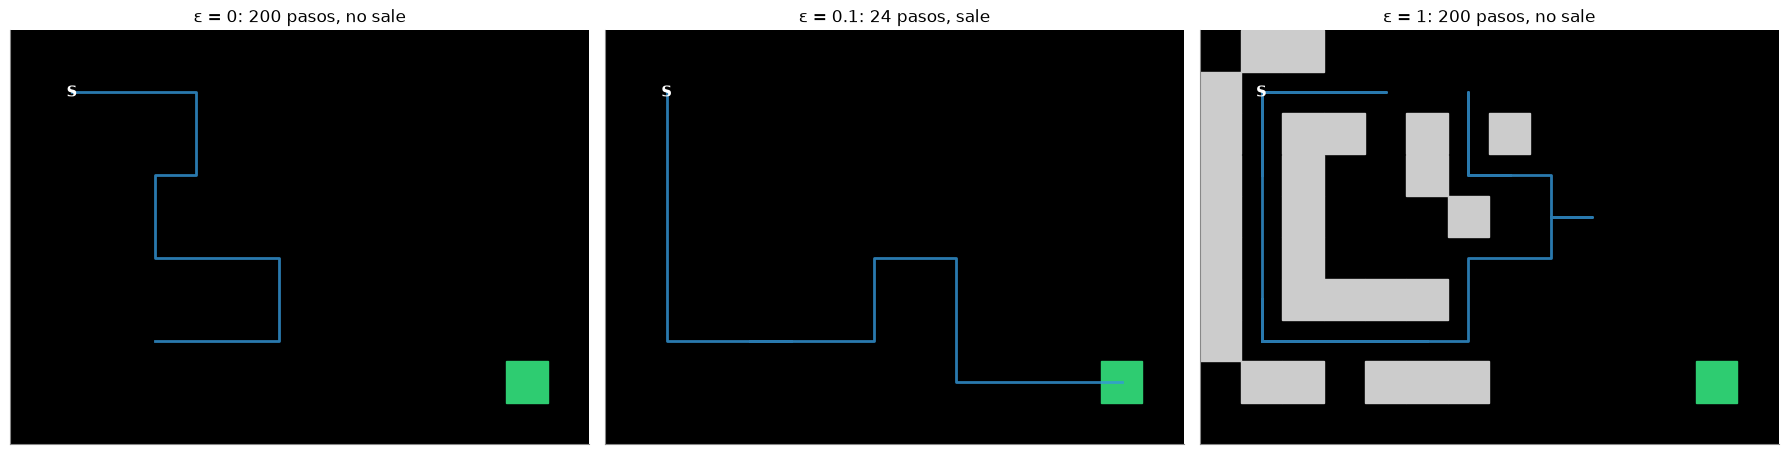

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, e in zip(axs, [0, 0.1, 1]):
    p = jugar(env, barrido[e][0]["Q"], e, np.random.default_rng(1))
    salio = p[-1][3] == env.goal
    plot_agent_view(env, p, ax, f"ε = {e:g}: {len(p)} pasos, " + ("sale" if salio else "no sale"))
    print(f"ε = {e:<4g} pasos = {len(p):3d}   ¿salió? {'sí' if salio else 'no'}   casillas distintas = {len(set(camino_de(p)))}   "
          f"choques = {sum(x[0] == x[3] for x in p)}")
plt.tight_layout(); plt.show()

Con $\varepsilon = 0$ el agente va y viene por el mismo recorrido de 17 casillas durante los 200 pasos: sin probar, no hay de dónde aprender. Con $\varepsilon = 0{,}1$ va casi derecho a la salida. Con $\varepsilon = 1$ deambula al azar y choca contra las paredes una y otra vez. **Probar cuesta pasos, pero sin probar no se aprende nada.**

## 3. SARSA: aprender de lo que hago

La idea es la de TD(0) de la clase 5, pero sobre $Q$: después de cada paso, corregir el valor de la flecha que se usó hacia un objetivo que mira un paso adelante. En **SARSA** el objetivo usa **la acción que de verdad va a tomar** en la casilla siguiente, $a'$ (elegida con el mismo $\varepsilon$-greedy, así que a veces es al azar):

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\,r + \gamma\, Q(s', a') - Q(s,a)\,\big]$$

El nombre sale de los cinco datos que usa cada actualización: $(s, a, r, s', a')$, *State–Action–Reward–State–Action*.

### Paso 1 — Un agente a medio aprender

Dejamos que SARSA juegue 300 partidas desde S con $\varepsilon = 0{,}2$ y $\alpha = 0{,}2$. Después lo hacemos jugar una partida más, sin aprender, y buscamos un paso en el que **la acción siguiente $a'$ salió al azar** y no es la mejor. Ese paso es el que vamos a actualizar a mano.

Partida de 38 pasos. El paso elegido:
   s = (3, 6)   a = ↑   r = 0   s' = (2, 6)   a' = ← (salió al azar; la mejor en s' era ↑)
Q(s, ·)  = ↑ 0.3378   → 0.1777   ↓ 0.1690   ← 0.1822
Q(s', ·) = ↑ 0.3865   → 0.2755   ↓ 0.1204   ← 0.2372


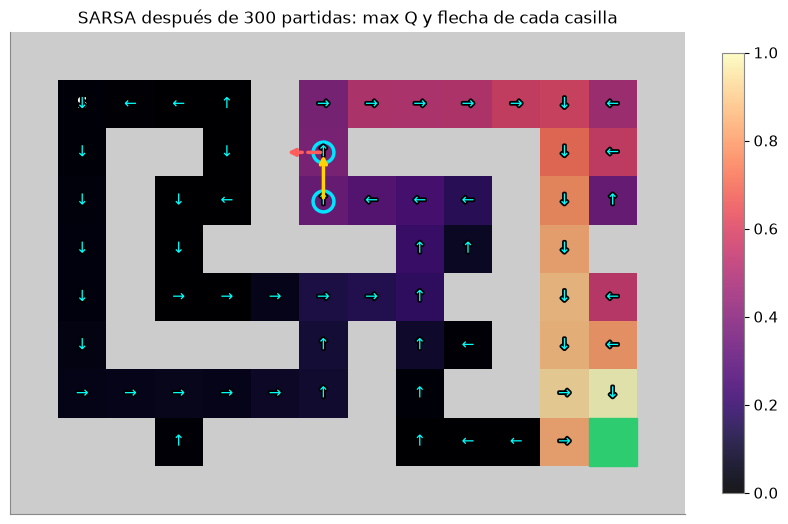

amarillo: el paso (s, a) -> s'.   rojo punteado: a', la acción que tomó después (al azar).


In [9]:
EPS = 0.2
sarsa300 = aprender(env, "sarsa", EPS, ALFA, 300, semilla=3)
Q_mano = sarsa300["Q"].copy()

rng = np.random.default_rng(7)
elegidos = []
while not elegidos:
    p = jugar(env, Q_mano, EPS, rng)
    elegidos = [x for x in p if x[5] and x[4] != Q_mano[x[3]].argmax() and x[2] == 0 and Q_mano[x[3]].max() > 0.3]
s, a, r, s2, a2, _ = elegidos[0]
print(f"Partida de {len(p)} pasos. El paso elegido:")
print(f"   s = {env.free[s]}   a = {ACTION_NAMES[a]}   r = {r:g}   s' = {env.free[s2]}   "
      f"a' = {ACTION_NAMES[a2]} (salió al azar; la mejor en s' era {ACTION_NAMES[int(Q_mano[s2].argmax())]})")
print("Q(s, ·)  = " + "   ".join(f"{ACTION_NAMES[b]} {Q_mano[s, b]:.4f}" for b in range(env.nA)))
print("Q(s', ·) = " + "   ".join(f"{ACTION_NAMES[b]} {Q_mano[s2, b]:.4f}" for b in range(env.nA)))

fig, ax = plt.subplots(figsize=(8, 5.6))
plot_cave(env, values=Q_mano.max(axis=1), policy=Q_mano.argmax(axis=1), mark=[s, s2], clim=(0, V_estrella[ng].max()), ax=ax,
          title="SARSA después de 300 partidas: max Q y flecha de cada casilla")
(r0, c0), (r1, c1) = env.free[s], env.free[s2]
ax.annotate("", xy=(c1, r1), xytext=(c0, r0), arrowprops=dict(arrowstyle="->", color="#ffd400", lw=2.5))
dr, dc = [(-1, 0), (0, 1), (1, 0), (0, -1)][a2]
ax.annotate("", xy=(c1 + 0.8 * dc, r1 + 0.8 * dr), xytext=(c1, r1),
            arrowprops=dict(arrowstyle="->", color="#ff5c5c", lw=2.5, ls="--"))
plt.tight_layout(); plt.show()
print("amarillo: el paso (s, a) -> s'.   rojo punteado: a', la acción que tomó después (al azar).")

### Paso 2 — La actualización de SARSA, con números

1. El **objetivo**: el premio que cobró más lo que espera de la acción que de verdad va a tomar, $r + \gamma\,Q(s', a')$.
2. El **error** $\delta$: objetivo menos lo que creía, $Q(s, a)$.
3. La **corrección**: $Q(s,a)$ se mueve una fracción $\alpha$ del error.

In [10]:
obj_sarsa = r + GAMMA * Q_mano[s2, a2]
delta_sarsa = obj_sarsa - Q_mano[s, a]
nuevo_sarsa = Q_mano[s, a] + ALFA * delta_sarsa
print(f"Paso: {env.free[s]} --{ACTION_NAMES[a]}--> {env.free[s2]},  r = {r:g},  a' = {ACTION_NAMES[a2]},  α = {ALFA},  γ = {GAMMA}")
print(f"   1. objetivo SARSA = r + γ Q(s', a') = {r:g} + {GAMMA} · {Q_mano[s2, a2]:.4f} = {obj_sarsa:.4f}")
print(f"   2. δ = objetivo − Q(s, a) = {obj_sarsa:.4f} − {Q_mano[s, a]:.4f} = {delta_sarsa:+.4f}")
print(f"   3. Q(s, a) nuevo = Q(s, a) + α δ = {Q_mano[s, a]:.4f} + {ALFA} · ({delta_sarsa:+.4f}) = {nuevo_sarsa:.4f}")
print(f"   (respuesta correcta, con el mapa: Q*(s, a) = {Q_estrella[s, a]:.4f})")

Paso: (3, 6) --↑--> (2, 6),  r = 0,  a' = ←,  α = 0.2,  γ = 0.99
   1. objetivo SARSA = r + γ Q(s', a') = 0 + 0.99 · 0.2372 = 0.2348
   2. δ = objetivo − Q(s, a) = 0.2348 − 0.3378 = -0.1030
   3. Q(s, a) nuevo = Q(s, a) + α δ = 0.3378 + 0.2 · (-0.1030) = 0.3172
   (respuesta correcta, con el mapa: Q*(s, a) = 0.8864)


La acción siguiente salió al azar y vale menos que la mejor de $s'$, así que el objetivo de SARSA queda **bajo** (en este paso, más bajo que lo que ya creía: $\delta$ es negativo y $Q(s, a)$ baja). SARSA le cobra a la flecha $a$ el desvío que el agente va a hacer después. Eso es «aprender de lo que hago»: el valor que aprende SARSA incluye sus propias pruebas.

## 4. Q-learning: aprender de lo mejor que podría hacer

**Q-learning** (Watkins y Dayan, 1992) cambia un solo término del objetivo: en vez de la acción que va a tomar, usa **la mejor** de la casilla siguiente, aunque después no la tome:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\,r + \gamma\, \max_{a'} Q(s', a') - Q(s,a)\,\big]$$

### Paso 1 — La misma experiencia, con la otra regla

Mismo paso, misma tabla $Q$, mismos $\alpha$ y $\gamma$. Lo único que cambia es el objetivo.

In [11]:
mejor2 = int(Q_mano[s2].argmax())
obj_q = r + GAMMA * Q_mano[s2].max()
delta_q = obj_q - Q_mano[s, a]
nuevo_q = Q_mano[s, a] + ALFA * delta_q
print(f"Paso: {env.free[s]} --{ACTION_NAMES[a]}--> {env.free[s2]},  r = {r:g},  α = {ALFA},  γ = {GAMMA}")
print(f"   1. objetivo Q-learning = r + γ max Q(s', ·) = {r:g} + {GAMMA} · {Q_mano[s2].max():.4f} "
      f"(la de {ACTION_NAMES[mejor2]}) = {obj_q:.4f}")
print(f"   2. δ = objetivo − Q(s, a) = {obj_q:.4f} − {Q_mano[s, a]:.4f} = {delta_q:+.4f}")
print(f"   3. Q(s, a) nuevo = Q(s, a) + α δ = {Q_mano[s, a]:.4f} + {ALFA} · ({delta_q:+.4f}) = {nuevo_q:.4f}")
print(f"\nLa misma experiencia:  SARSA deja Q(s, a) = {nuevo_sarsa:.4f}   Q-learning lo deja en {nuevo_q:.4f}   "
      f"(Q*(s, a) = {Q_estrella[s, a]:.4f})")
print(f"La diferencia sale del objetivo: Q(s', a' = {ACTION_NAMES[a2]}) = {Q_mano[s2, a2]:.4f}  contra  "
      f"max Q(s', ·) = {Q_mano[s2].max():.4f}")

Paso: (3, 6) --↑--> (2, 6),  r = 0,  α = 0.2,  γ = 0.99
   1. objetivo Q-learning = r + γ max Q(s', ·) = 0 + 0.99 · 0.3865 (la de ↑) = 0.3827
   2. δ = objetivo − Q(s, a) = 0.3827 − 0.3378 = +0.0449
   3. Q(s, a) nuevo = Q(s, a) + α δ = 0.3378 + 0.2 · (+0.0449) = 0.3468

La misma experiencia:  SARSA deja Q(s, a) = 0.3172   Q-learning lo deja en 0.3468   (Q*(s, a) = 0.8864)
La diferencia sale del objetivo: Q(s', a' = ←) = 0.2372  contra  max Q(s', ·) = 0.3865


Q-learning **no le cobra** a la flecha $a$ el desvío que viene después: aprende cuánto valdría $a$ si de ahí en adelante el agente jugara lo mejor que sabe. Por eso se dice que es ***off-policy***: aprende el valor de una política (la mejor) mientras juega otra (la que explora). SARSA es ***on-policy***: aprende el valor de la misma política con la que juega.

### Paso 2 — Los dos, aprendiendo desde cero

SARSA y Q-learning, 500 partidas desde S, $\varepsilon = 0{,}2$, $\alpha = 0{,}2$, 5 semillas cada uno. A la izquierda, cuántos pasos tarda cada partida; a la derecha, cuánto cree que vale S, $\max_a Q(S, a)$, contra $V^*(S)$.

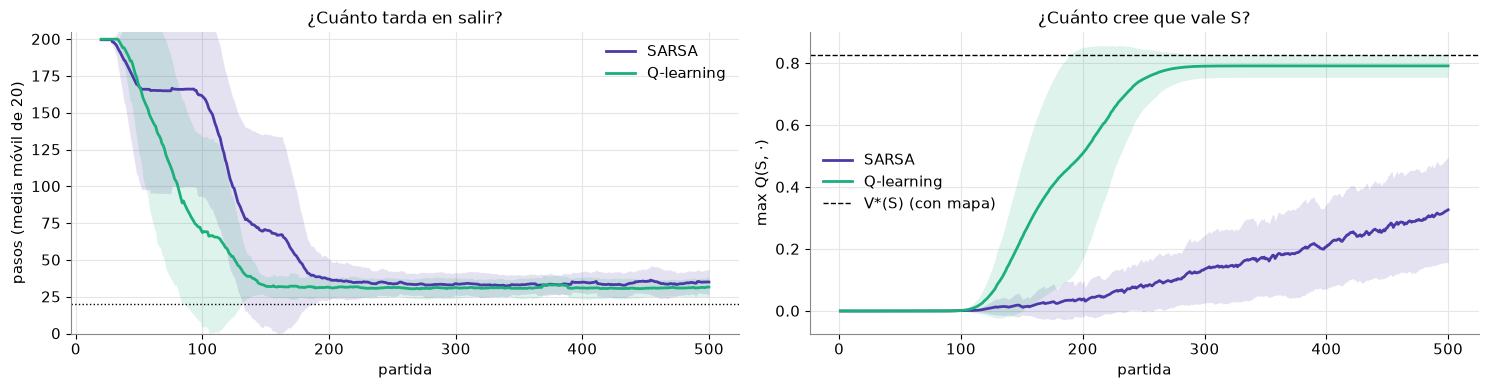

SARSA      primera salida en las partidas [77, 15, 163, 98, 29]   pasos (últimas 100) = 34.3   max Q(S) al final = 0.3268 ± 0.1699   [0.3808, 0.4704, 0.1372, 0.1168, 0.5288]
Q-learning primera salida en las partidas [49, 34, 83, 73, 43]   pasos (últimas 100) = 31.0   max Q(S) al final = 0.7913 ± 0.0368   [0.8097, 0.8097, 0.8097, 0.7177, 0.8097]
V*(S) = 0.8262


In [12]:
SEMILLAS = range(5)
corridas = {m: [aprender(env, m, EPS, ALFA, 500, sem) for sem in SEMILLAS] for m in ["sarsa", "q"]}

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for m in corridas:
    pasos = np.array([suavizar(c["pasos"]) for c in corridas[m]])
    banda(axs[0], np.arange(pasos.shape[1]) + 20, pasos, COLOR[m], NOMBRE[m])
    vs = np.array([c["VS"] for c in corridas[m]])
    banda(axs[1], np.arange(1, vs.shape[1] + 1), vs, COLOR[m], NOMBRE[m])
axs[0].axhline(20, color="k", ls=":", lw=1); axs[0].set_ylim(0, 205)
axs[0].set_xlabel("partida"); axs[0].set_ylabel("pasos (media móvil de 20)"); axs[0].set_title("¿Cuánto tarda en salir?")
axs[1].axhline(V_estrella[env.start], color="k", ls="--", lw=1, label="V*(S) (con mapa)")
axs[1].set_xlabel("partida"); axs[1].set_ylabel("max Q(S, ·)"); axs[1].set_title("¿Cuánto cree que vale S?")
for ax in axs:
    ax.legend(frameon=False, loc="best")
plt.tight_layout(); plt.show()

for m in corridas:
    f = [int(np.argmax(c["salio"])) + 1 for c in corridas[m]]
    vf = np.array([c["VS"][-1] for c in corridas[m]])
    pf = np.mean([c["pasos"][-100:].mean() for c in corridas[m]])
    print(f"{NOMBRE[m]:10s} primera salida en las partidas {f}   pasos (últimas 100) = {pf:.1f}   "
          f"max Q(S) al final = {vf.mean():.4f} ± {vf.std():.4f}   {np.round(vf, 4).tolist()}")
print(f"V*(S) = {V_estrella[env.start]:.4f}")

Los dos aprenden a salir en un par de cientos de partidas y al final juegan parecido (el $\varepsilon = 0{,}2$ los desvía a los dos por igual). Lo que cambia es **cuánto creen que vale S**: Q-learning se planta cerca de $V^*(S)$ (algunas semillas, en el valor de un camino algo más largo); SARSA queda mucho más abajo y todavía sube despacio, porque le cobra a S todos los desvíos de la exploración, incluidos los que lo llevan a casillas que todavía no aprendió. La sección siguiente mide esa diferencia con cuidado, con muchas más partidas.

## 5. SARSA contra Q-learning con varios $\varepsilon$

La predicción, a partir de los objetivos:

- **Q-learning** (*off-policy*) aprende $Q^*$, el valor de jugar perfecto, **sea cual sea $\varepsilon$**: su $\max_a Q(S, a)$ tendría que llegar a $V^*(S) = 0{,}8262$.
- **SARSA** (*on-policy*) aprende el valor de jugar **explorando con ese $\varepsilon$**: cuanto más explora, más pasos de más y menos vale S. Ese valor también lo podemos calcular con el mapa (`valor_explorando`): es lo que vale cada flecha si después se sigue jugando $\varepsilon$-greedy.

### Paso 1 — Cuatro valores de $\varepsilon$, 5 semillas

Para que todas las casillas reciban visitas y los valores lleguen a asentarse, en esta sección **cada partida empieza en una casilla al azar** (como en la clase 5) y jugamos 20 000 partidas con $\alpha = 0{,}2$. Leemos $\max_a Q(S, a)$ promediado en las últimas 2000 partidas (con $\alpha$ fijo, el valor tiembla un poco). Tarda unos 30 segundos.

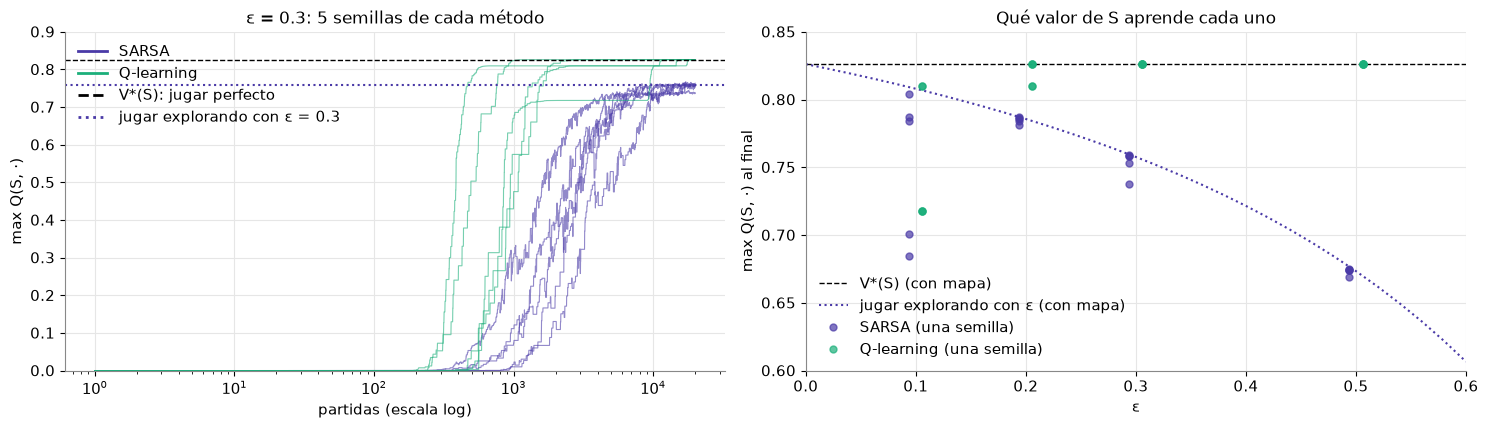

V*(S) = 0.8262.  max Q(S, ·), promedio de las últimas 2000 partidas, 5 semillas:
    ε         Q-learning              SARSA  explorando (mapa)
  0.1     0.7545 ± 0.0451     0.7523 ± 0.0493             0.8080
  0.2     0.8196 ± 0.0081     0.7850 ± 0.0021             0.7857
  0.3     0.8262 ± 0.0000     0.7534 ± 0.0081             0.7577
  0.5     0.8262 ± 0.0000     0.6734 ± 0.0022             0.6734

semilla por semilla:
   ε = 0.1  Q-learning [0.8097, 0.7177, 0.7177, 0.7177, 0.8097]   SARSA [0.7871, 0.7007, 0.6849, 0.7843, 0.8042]
   ε = 0.2  Q-learning [0.8262, 0.8097, 0.8262, 0.8262, 0.8097]   SARSA [0.7872, 0.7856, 0.7843, 0.7814, 0.7867]
   ε = 0.3  Q-learning [0.8262, 0.8262, 0.8262, 0.8261, 0.8262]   SARSA [0.7529, 0.7379, 0.7582, 0.7595, 0.7585]
   ε = 0.5  Q-learning [0.8262, 0.8262, 0.8262, 0.8262, 0.8262]   SARSA [0.6745, 0.6741, 0.6751, 0.6742, 0.669]


In [13]:
EPS_COMP = [0.1, 0.2, 0.3, 0.5]
N_COMP = 20_000
comp = {(m, e): [aprender(env, m, e, ALFA, N_COMP, sem, inicio="azar") for sem in SEMILLAS]
        for e in EPS_COMP for m in ["sarsa", "q"]}
VS_fin = {k: np.array([c["VS"][-2000:].mean() for c in v]) for k, v in comp.items()}
Q_eps = {e: valor_explorando(env, GAMMA, e) for e in EPS_COMP}

eps_fino = np.linspace(0, 0.6, 31)
ref_fina = [valor_explorando(env, GAMMA, e)[env.start].max() for e in eps_fino]

fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
e_ver = 0.3
for m in ["sarsa", "q"]:
    for i, c in enumerate(comp[(m, e_ver)]):
        axs[0].plot(np.arange(1, N_COMP + 1), c["VS"], color=COLOR[m], lw=0.8, alpha=0.6,
                    label=NOMBRE[m] if i == 0 else None)
axs[0].axhline(V_estrella[env.start], color="k", ls="--", lw=1, label="V*(S): jugar perfecto")
axs[0].axhline(Q_eps[e_ver][env.start].max(), color=COL_SARSA, ls=":", lw=1.5, label=f"jugar explorando con ε = {e_ver}")
axs[0].set_xscale("log"); axs[0].set_ylim(0, 0.9); axs[0].set_xlabel("partidas (escala log)")
axs[0].set_ylabel("max Q(S, ·)"); axs[0].set_title(f"ε = {e_ver}: 5 semillas de cada método")
for l_ in axs[0].legend(frameon=False, loc="upper left").get_lines():
    l_.set_linewidth(2); l_.set_alpha(1)

axs[1].plot(eps_fino, np.full_like(eps_fino, V_estrella[env.start]), "k--", lw=1, label="V*(S) (con mapa)")
axs[1].plot(eps_fino, ref_fina, ":", color=COL_SARSA, lw=1.5, label="jugar explorando con ε (con mapa)")
for m, desp in [("sarsa", -0.006), ("q", 0.006)]:
    for e in EPS_COMP:
        axs[1].plot(np.full(len(SEMILLAS), e + desp), VS_fin[(m, e)], "o", color=COLOR[m], ms=5, alpha=0.7,
                    label=NOMBRE[m] + " (una semilla)" if e == EPS_COMP[0] else None)
axs[1].set_xlim(0, 0.6); axs[1].set_ylim(0.6, 0.85); axs[1].set_xlabel("ε"); axs[1].set_ylabel("max Q(S, ·) al final")
axs[1].set_title("Qué valor de S aprende cada uno"); axs[1].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

print(f"V*(S) = {V_estrella[env.start]:.4f}.  max Q(S, ·), promedio de las últimas 2000 partidas, 5 semillas:")
print(f"{'ε':>5s} {'Q-learning':>18s} {'SARSA':>18s} {'explorando (mapa)':>18s}")
for e in EPS_COMP:
    q_, s_ = VS_fin[("q", e)], VS_fin[("sarsa", e)]
    print(f"{e:>5g} {q_.mean():>10.4f} ± {q_.std():.4f} {s_.mean():>10.4f} ± {s_.std():.4f} {Q_eps[e][env.start].max():>18.4f}")
print("\nsemilla por semilla:")
for e in EPS_COMP:
    print(f"   ε = {e:<4g} Q-learning {np.round(VS_fin[('q', e)], 4).tolist()}   SARSA {np.round(VS_fin[('sarsa', e)], 4).tolist()}")

Lo que muestran los números:

- **SARSA**, con $\varepsilon$ de 0,2 a 0,5, queda casi sobre la línea punteada: aprende cuánto vale S **jugando como juega**, con sus pruebas incluidas. Cuanto más grande $\varepsilon$, más bajo.
- **Q-learning** llega a $V^*(S)$ con $\varepsilon$ 0,3 y 0,5, aunque juega explorando: aprende el valor de jugar perfecto. Con $\varepsilon = 0{,}2$, dos semillas quedan clavadas en un valor algo más bajo: aprendieron perfecto el valor de **otro camino**, más largo, y nunca probaron lo suficiente el más corto.
- Con $\varepsilon = 0{,}1$ los dos quedan por debajo de lo que les corresponde, y parecidos entre sí: con tan poca exploración, 20 000 partidas no alcanzan. La diferencia entre *on-policy* y *off-policy* se ve cuando la exploración alcanza.

### Paso 2 — ¿Qué camino creen que hay?

Si el único premio es el +1, un valor $V$ corresponde a un camino de $n$ pasos con $V = \gamma^{\,n-1}$. Traducimos el valor de S de cada semilla a pasos, y medimos además qué fracción de las flechas aprendidas son óptimas.

In [14]:
for m in ["q", "sarsa"]:
    print(f"{NOMBRE[m]}:")
    for e in EPS_COMP:
        n_pasos = np.round(pasos_de(VS_fin[(m, e)]), 1).tolist()
        fr = np.mean([frac_optimas(env, c["Q"], opt) for c in comp[(m, e)]])
        print(f"   ε = {e:<4g} V(S) traducido a pasos: {str(n_pasos):34s} flechas óptimas: {fr:.0%}")
print(f"\n(camino más corto: {pasos_de(V_estrella[env.start]):.0f} pasos; 'flechas óptimas' = fracción de casillas, sin la salida, "
      f"en las que la flecha de mayor Q es óptima, promedio de 5 semillas)")

Q-learning:
   ε = 0.1  V(S) traducido a pasos: [22.0, 34.0, 34.0, 34.0, 22.0]     flechas óptimas: 82%
   ε = 0.2  V(S) traducido a pasos: [20.0, 22.0, 20.0, 20.0, 22.0]     flechas óptimas: 99%
   ε = 0.3  V(S) traducido a pasos: [20.0, 20.0, 20.0, 20.0, 20.0]     flechas óptimas: 100%
   ε = 0.5  V(S) traducido a pasos: [20.0, 20.0, 20.0, 20.0, 20.0]     flechas óptimas: 100%
SARSA:
   ε = 0.1  V(S) traducido a pasos: [24.8, 36.4, 38.7, 25.2, 22.7]     flechas óptimas: 88%
   ε = 0.2  V(S) traducido a pasos: [24.8, 25.0, 25.2, 25.5, 24.9]     flechas óptimas: 98%
   ε = 0.3  V(S) traducido a pasos: [29.2, 31.2, 28.5, 28.4, 28.5]     flechas óptimas: 100%
   ε = 0.5  V(S) traducido a pasos: [40.2, 40.2, 40.1, 40.2, 41.0]     flechas óptimas: 100%

(camino más corto: 20 pasos; 'flechas óptimas' = fracción de casillas, sin la salida, en las que la flecha de mayor Q es óptima, promedio de 5 semillas)


Las semillas de Q-learning que quedaron abajo creen en un camino más largo que el de 20 pasos: su valor es exacto **para ese camino**, pero el más corto sale de S hacia la derecha y casi no lo exploraron. Q-learning promete $Q^*$ solo si **todas** las flechas se siguen probando; con poca exploración, aprende lo mejor de lo que vio.

Los «pasos» de SARSA no son un camino de verdad: su valor promedia los desvíos de la exploración, y por eso equivale a un camino más largo que el que de verdad sigue.

> **Para enseñarlo:** SARSA aprende de lo que de verdad hago; Q-learning, de lo mejor que podría hacer desde ahí.

¿Cuál conviene? Si el agente va a **seguir explorando** (y los desvíos pueden costar caro, por ejemplo cerca de un precipicio), el valor de SARSA es una predicción honesta de lo que va a cobrar. Si la exploración es solo para aprender y después se juega sin ella, el de Q-learning es el que importa.

## 6. El mapa de visitas

El agente solo puede aprender de las casillas por las que pasa. Volvemos al juego: **partidas desde S**, Q-learning, $\varepsilon = 0{,}1$, $\alpha = 0{,}2$, 2000 partidas. Contamos cuántas veces pisó cada casilla y lo comparamos con dónde se equivoca: el error de su valor, $|\max_a Q(s,a) - V^*(s)|$, y si la flecha aprendida es óptima.

### Paso 1 — Visitas, error y flechas

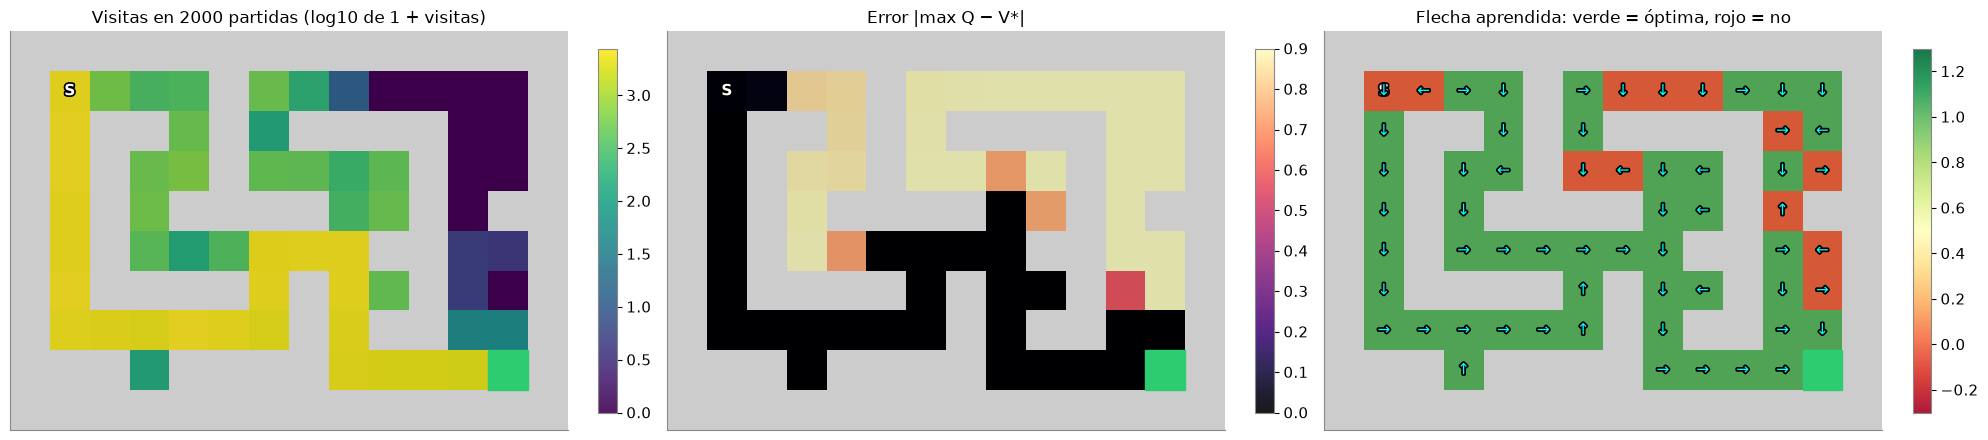

semilla 0: max Q(S) = 0.8097  (V*(S) = 0.8262; equivale a un camino de 22 pasos)
flecha aprendida en S: ↓   flecha óptima en S: →
flechas óptimas: 80% de las casillas   casillas nunca pisadas: 10: (1, 9), (1, 10), (1, 11), (1, 12), (2, 11), (2, 12), (3, 11), (3, 12), (4, 11), (6, 12)

las 8 casillas menos visitadas:
   (1, 9)    visitas =     0   max Q = 0.0001   V* = 0.9135   error = 0.9134   flecha NO óptima
   (1, 12)   visitas =     0   max Q = 0.0001   V* = 0.9227   error = 0.9227   flecha óptima
   (1, 11)   visitas =     0   max Q = 0.0001   V* = 0.9321   error = 0.9320   flecha óptima
   (2, 11)   visitas =     0   max Q = 0.0001   V* = 0.9415   error = 0.9414   flecha NO óptima
   (2, 12)   visitas =     0   max Q = 0.0001   V* = 0.9321   error = 0.9320   flecha óptima
   (1, 10)   visitas =     0   max Q = 0.0001   V* = 0.9227   error = 0.9227   flecha óptima
   (3, 12)   visitas =     0   max Q = 0.0001   V* = 0.9415   error = 0.9414   flecha NO óptima
   (3, 11)   visitas =

In [15]:
EPS_VIS = 0.1
vis_corridas = [aprender(env, "q", EPS_VIS, ALFA, 2000, sem) for sem in SEMILLAS]
c0 = vis_corridas[0]
visitas = c0["visitas"].sum(axis=0)
err = np.abs(c0["Q"].max(axis=1) - V_estrella)
bien = opt[np.arange(env.nS), c0["Q"].argmax(axis=1)]

fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
plot_cave(env, values=np.log10(1 + visitas), ax=axs[0], cmap="viridis", title="Visitas en 2000 partidas (log10 de 1 + visitas)")
plot_cave(env, values=err, ax=axs[1], cmap="magma", clim=(0, 0.9), title="Error |max Q − V*|")
plot_cave(env, values=np.where(bien, 1.0, 0.0), policy=c0["Q"].argmax(axis=1), ax=axs[2], cmap="RdYlGn", clim=(-0.3, 1.3),
          title="Flecha aprendida: verde = óptima, rojo = no")
plt.tight_layout(); plt.show()

print(f"semilla 0: max Q(S) = {c0['Q'][env.start].max():.4f}  (V*(S) = {V_estrella[env.start]:.4f}; "
      f"equivale a un camino de {pasos_de(c0['Q'][env.start].max()):.0f} pasos)")
print(f"flecha aprendida en S: {ACTION_NAMES[int(c0['Q'][env.start].argmax())]}   flecha óptima en S: "
      f"{', '.join(ACTION_NAMES[a_] for a_ in np.flatnonzero(opt[env.start]))}")
print(f"flechas óptimas: {frac_optimas(env, c0['Q'], opt):.0%} de las casillas   casillas nunca pisadas: {int(np.sum(visitas[ng] == 0))}: "
      f"{', '.join(str(env.free[s_]) for s_ in np.flatnonzero(ng & (visitas == 0)))}")
orden = [int(x) for x in np.argsort(np.where(ng, visitas, np.inf))][:int(ng.sum())]
def fila(s_):
    return (f"   {str(env.free[s_]):9s} visitas = {visitas[s_]:5d}   max Q = {c0['Q'][s_].max():.4f}   V* = {V_estrella[s_]:.4f}   "
            f"error = {err[s_]:.4f}   flecha {'óptima' if bien[s_] else 'NO óptima'}")
print("\nlas 8 casillas menos visitadas:")
for s_ in orden[:8]:
    print(fila(s_))
print("las 5 más visitadas:")
for s_ in orden[-5:][::-1]:
    print(fila(s_))

El error es casi 0 solo sobre el camino que usa el agente (las casillas amarillas del primer mapa, pisadas miles de veces). Fuera de ese camino el valor quedó cerca de 0 y el error cerca de 0,9, aunque algunas de esas casillas se pisaron cientos de veces: pasar de vez en cuando, explorando, no alcanza para que el +1 llegue hasta ahí. De las 10 casillas que no pisó nunca, 9 están arriba a la derecha. Casi todas las flechas rojas están fuera del camino, salvo una que importa mucho: **la de S**, que apunta hacia abajo (el camino de 22 pasos) y no a la derecha (el de 20).

### Paso 2 — Visitas contra error, en 5 semillas

Una figura con todas las casillas de las 5 semillas: en el eje horizontal, cuántas veces la pisó; en el vertical, cuánto se equivoca su valor.

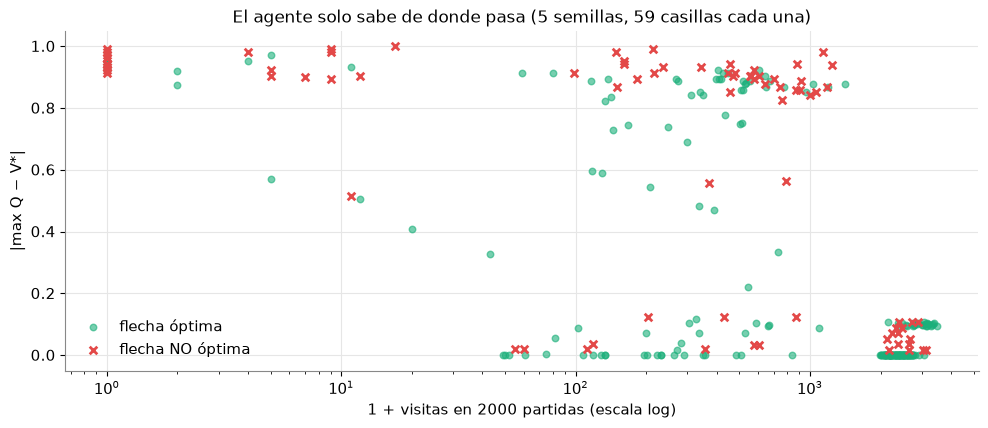

       visitas  casillas  error medio  flechas óptimas
           0–9        32       0.9305              41%
         10–99        18       0.4130              67%
       100–999       106       0.5580              65%
    1000 o más       139       0.0775              86%

max Q(S) de las 5 semillas: [0.8097, 0.8097, 0.7323, 0.7177, 0.8262]   (V*(S) = 0.8262)
flechas óptimas de las 5 semillas: ['80%', '68%', '69%', '68%', '76%']


In [16]:
V_todas, E_todas, B_todas = [], [], []
for c in vis_corridas:
    V_todas.append(c["visitas"].sum(axis=0)[ng])
    E_todas.append(np.abs(c["Q"].max(axis=1) - V_estrella)[ng])
    B_todas.append(opt[np.arange(env.nS), c["Q"].argmax(axis=1)][ng])
V_todas, E_todas, B_todas = map(np.concatenate, (V_todas, E_todas, B_todas))

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.scatter(1 + V_todas[B_todas], E_todas[B_todas], s=22, color=COL_Q, alpha=0.6, label="flecha óptima")
ax.scatter(1 + V_todas[~B_todas], E_todas[~B_todas], s=30, color=COLORES[7], marker="x", label="flecha NO óptima")
ax.set_xscale("log"); ax.set_xlabel("1 + visitas en 2000 partidas (escala log)"); ax.set_ylabel("|max Q − V*|")
ax.set_title("El agente solo sabe de donde pasa (5 semillas, 59 casillas cada una)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(f"{'visitas':>14s} {'casillas':>9s} {'error medio':>12s} {'flechas óptimas':>16s}")
for lo, hi in [(0, 10), (10, 100), (100, 1000), (1000, None)]:
    sel = (V_todas >= lo) & (True if hi is None else V_todas < hi)
    rango = f"{lo} o más" if hi is None else f"{lo}–{hi - 1}"
    if np.any(sel):
        print(f"{rango:>14s} {int(sel.sum()):>9d} {E_todas[sel].mean():>12.4f} {B_todas[sel].mean():>16.0%}")
print(f"\nmax Q(S) de las 5 semillas: {[round(float(c['Q'][env.start].max()), 4) for c in vis_corridas]}   (V*(S) = {V_estrella[env.start]:.4f})")
print(f"flechas óptimas de las 5 semillas: {[format(frac_optimas(env, c['Q'], opt), '.0%') for c in vis_corridas]}")

Con menos de 10 visitas, el agente no sabe nada (error cerca de 0,9, la mayoría de las flechas equivocadas); con 1000 o más, el error es chico. En el medio hay de todo: casillas que se pisan cientos de veces, pero solo de paso, y no llegan a asentar su valor. Al agente no le molesta mientras no pase por ahí, pero si una de esas casillas está en el camino más corto, nunca se va a enterar de que por ahí se llegaba antes. Tirar una moneda con $\varepsilon = 0{,}1$ no alcanza para llegar a todos lados: **cómo explorar mejor** es el tema de la clase 7.

## ✍️ Ejercicio — Cambien $\varepsilon$ y $\alpha$

Cambien `eps_ej` y `alfa_ej` y ejecuten. La celda corre SARSA y Q-learning desde S, 2000 partidas, 3 semillas, y muestra el valor de S de cada uno contra $V^*(S)$, las flechas óptimas y el mapa de visitas de Q-learning.

Antes de ejecutar, **predigan**: con $\varepsilon = 0{,}5$, ¿cuál de los dos queda más cerca de $V^*(S) = 0{,}8262$? ¿Y con $\varepsilon = 0{,}02$, qué pasa con las casillas sin visitar? Con $\alpha = 0{,}9$, ¿tiembla más el valor de SARSA o el de Q-learning?

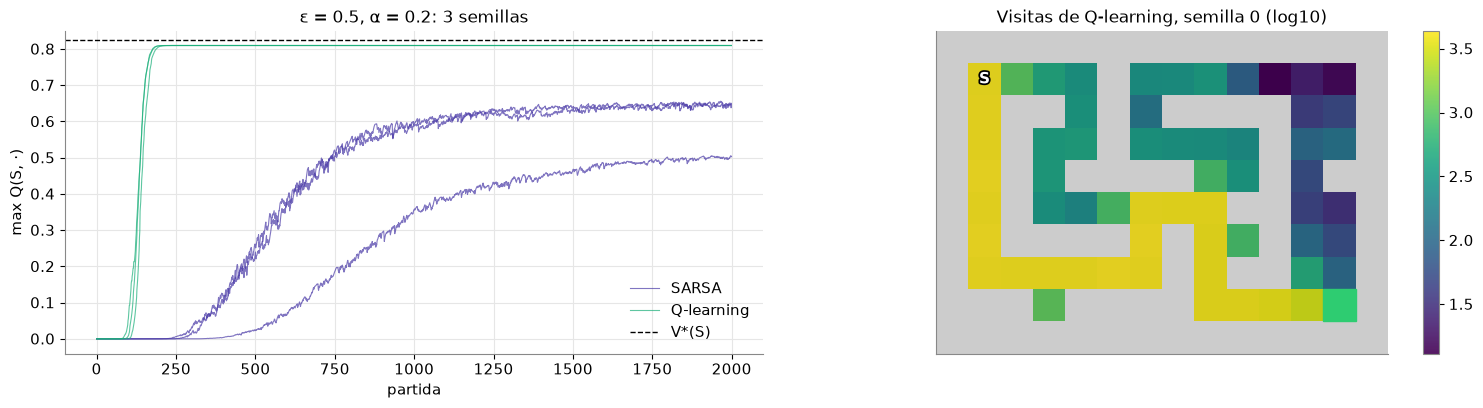

SARSA      max Q(S) final = [0.6406, 0.5036, 0.6446]   flechas óptimas = ['92%', '83%', '95%']   casillas nunca pisadas = [0, 0, 0]
Q-learning max Q(S) final = [0.8097, 0.8097, 0.8097]   flechas óptimas = ['88%', '75%', '83%']   casillas nunca pisadas = [0, 0, 0]
V*(S) = 0.8262


In [17]:
eps_ej = 0.5     # TODO: probá 0.02, 0.1, 0.5
alfa_ej = 0.2    # TODO: probá 0.05, 0.9

ej = {m: [aprender(env, m, eps_ej, alfa_ej, 2000, sem) for sem in range(3)] for m in ["sarsa", "q"]}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
for m in ej:
    for i, c in enumerate(ej[m]):
        axs[0].plot(c["VS"], color=COLOR[m], lw=0.8, alpha=0.7, label=NOMBRE[m] if i == 0 else None)
axs[0].axhline(V_estrella[env.start], color="k", ls="--", lw=1, label="V*(S)")
axs[0].set_xlabel("partida"); axs[0].set_ylabel("max Q(S, ·)"); axs[0].legend(frameon=False)
axs[0].set_title(f"ε = {eps_ej}, α = {alfa_ej}: 3 semillas")
plot_cave(env, values=np.log10(1 + ej["q"][0]["visitas"].sum(axis=0)), ax=axs[1], cmap="viridis",
          title="Visitas de Q-learning, semilla 0 (log10)")
plt.tight_layout(); plt.show()
for m in ej:
    vs_ = [round(float(c["VS"][-1]), 4) for c in ej[m]]
    fr_ = [format(frac_optimas(env, c["Q"], opt), ".0%") for c in ej[m]]
    nunca_ = [int(np.sum(c["visitas"].sum(0)[ng] == 0)) for c in ej[m]]
    print(f"{NOMBRE[m]:10s} max Q(S) final = {vs_}   flechas óptimas = {fr_}   casillas nunca pisadas = {nunca_}")
print(f"V*(S) = {V_estrella[env.start]:.4f}")

**Lo que encontramos** (¿quién queda más cerca de $V^*(S)$? ¿cómo cambian las visitas y las flechas con $\varepsilon$? ¿qué hace $\alpha$?):

-

## Preguntas para pensar

1. En la sección 2, con $\varepsilon = 0$ el agente casi nunca encontró la salida. ¿Qué cambiaría si el $Q$ inicial fuera 1 en todas las flechas en vez de 0? (Pista: ¿qué pasa con el valor de una flecha cada vez que la prueba y no encuentra nada?)
2. Imaginen un tutor que, para aprender qué ejercicio conviene, a veces le da a un alumno uno al azar. ¿Qué valor les parece más honesto para decidir: el de SARSA o el de Q-learning? ¿Quién paga los desvíos de la exploración?
3. En la sección 6, las casillas poco visitadas quedaron con valores y flechas equivocados. ¿En qué situación eso sería grave aunque el agente casi nunca pase por ahí?

## Próxima clase

El agente solo aprende de donde pasa, y tirar una moneda con probabilidad $\varepsilon$ es una manera bastante torpe de decidir adónde ir. En la clase 7, **explorar**: de los *bandits* (como elegir qué aviso mostrar en una página) a la cueva, con maneras de probar que apuntan adonde todavía no se sabe.